In [1]:
"""
time to go from the implanted images to the lightcurve parameters all in one go
"""

'\ntime to go from the implanted images to the lightcurve parameters all in one go\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm

import plot_time_series as pts
import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from tensorflow import keras
import get_postage_stamps as gpsf

Matplotlib is building the font cache; this may take a moment.


ModuleNotFoundError: No module named 'plot_time_series'

2024-12-04 17:29:34.009757: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [20]:
seed = np.random.seed(42)
size = 2000
center_values = np.random.randint(30, high=3042, size=size, dtype=int)
sigmas = np.random.randint(3, high=10, size=size, dtype=int)
intensities_pos = imp.get_intensities_pos(size, seed)

In [21]:
fpath_image = "/lustre/lrspec/ZTF_data/training_aug24/implant_train/"
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/"
size = 2000  # will cut to 1000
transient_info_list = []
optimized_params_list = []
saved_tots = []

counter = 0

for iteration in range(1, 4):
    for i, file in enumerate(os.listdir(fpath_image)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = fpath_image + image_filename
        imagepath = (
            path_to_save
            + "images/"
            + str(filename_start)
            + "_"
            + str(iteration)
            + "_implanted"
        )
        infopath = (
            path_to_save
            + "info/"
            + str(filename_start)
            + "_"
            + str(iteration)
            + "_implanted_info"
        )

        #         if os.path.isfile(infopath):
        #             print("skipping ",filename_start)
        #             continue

        print(image_filename)

        hdul = fits.open(image_filename_full)
        print(iteration)
        image = hdul[iteration].data
        # print(file1_array)

        nrow, ncol = image.shape
        # stamps_implanted, stamp_info  = imp.get_10_trans_stamps(image, sigmas,
        # intensities_pos,
        # center_values_new, counter, plot=False)
        implanted, transient_info = imp.implant_10_transients(
            image, sigmas, intensities_pos, center_values, counter=counter, plot=False
        )

        # np.save(imagepath, implanted)
        # np.save(infopath, transient_info)
        counter += len(transient_info) + 1
        if counter > 1990:
            break

ztf_20221017148750_000831_zi_c03_x_0007.fits.fz
1
[456, 457, 458, 455, 454]
trans xcoord etc:  (457, 890, 3.0, 7)
[1106, 1107, 1108, 1109, 1105, 1104]
trans xcoord etc:  (1108, 1324, 1.3, 7)
[1402, 1403, 1404, 1405, 1401, 1400]
trans xcoord etc:  (1404, 1160, 8.0, 8)
[1496, 1497, 1498, 1499, 1495, 1494]
trans xcoord etc:  (1497, 1125, 2.0, 7)
[1934, 1935, 1936, 1937, 1933]
trans xcoord etc:  (1936, 1668, 4.0, 3)
[3003, 3004, 3005, 3006, 3002]
trans xcoord etc:  (3005, 2199, 10.0, 8)
ztf_20220820237546_000798_zr_c09_x_0000.fits.fz
1
[75, 76, 74]
trans xcoord etc:  (75, 1268, 1.5, 6)
[432, 433, 434, 435, 436, 431]
trans xcoord etc:  (434, 360, 1.1, 7)
[549, 550, 551, 548, 547]
trans xcoord etc:  (548, 1512, 4.0, 9)
[627, 628, 629, 626]
trans xcoord etc:  (627, 2165, 3.0, 8)
[700, 701, 702, 699, 698]
trans xcoord etc:  (700, 2949, 1.05, 9)
[762, 763, 764, 765, 761]
trans xcoord etc:  (763, 160, 1.3, 3)
[1364, 1365, 1366, 1367, 1363]
trans xcoord etc:  (1365, 1715, 6.0, 6)
[1921, 1922, 192

KeyboardInterrupt: 

In [3]:
direcs = ["/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/"]

In [32]:
model_best = keras.models.load_model("/home/3155/CNN_sept2")


# In[68]:


def save_predsarrays(image, model, wid, path):
    """
    This function will take an image and a cnn model and return an array
    of the transients found in that image.
    image: np array
    model: cnn model
    abst_thr: absolute probability threshold to consider a transient probability as a transient
    mult_thr: comparative probability threshold to consider a transient probability as a transient
    (aka the trans prob has to be x times larger than (streak prob + backg prob)
    wid: desired postage stamp width
    bg_thresh: thresh to consider the average background on a column to be "background",
    something like .1, used as criterion for determining cosmic rays
    path: path to save the array

    returns (and saves): array of length (number of transient detections),
    with elements of (detection row, detection column), transient detection size,
    realness (aka not-cosmic-ray)
    so a list of tuples, then an int, then the probability that its column is a streak
    to flag as a probable cosmic ray
    """

    nrow, ncol = image.shape
    print("getting postage stamps")
    stamps = gpsf.get_postage_stamps_full(image, 10)
    stampbatches = np.array_split(
        stamps, stamps.shape[0] // 20000
    )  # (image.shape[0] - 2 * wid) )
    # I WANNA CHANGE THIS TO SPEED HIM UP
    # so to be faster there should be less batches
    # so i want the second argument to be smaller
    # so i want the denomitor of the second argument to be larger
    preds = []
    print("getting predictions:")
    for stamps in stampbatches:  # getting all the predictions. does not renormalize
        pred_l = model.predict_on_batch(stamps)
        preds.append(pred_l)
    predsarray = np.concatenate(preds)
    # i would like to save the predsarrays i think. for reproducibility
    np.save(path + "_predsarray", predsarray)  # TURN THIS BACK ON LATER
    del stamps
    del stampbatches
    del preds
    del predsarray
    gc.collect()
    return  # predsarray


# In[91]:

# '/lustre/lrspec/ZTF_data/science_extractions/to_extract/20210622_minus_extras/',
#


# ,
# , 1019

# In[87]:


for j in range(len(direcs)):
    direc = direcs[j]
    model = model_best
    wid = 10
    abst_thr = 0.9999
    fpath_extractions = (
        "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays/"
    )

    for i, file in enumerate(os.listdir(direc)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = direc + image_filename
        if os.path.isfile(
            fpath_extractions
            + str(filename_start)
            + "_extraction_predsarray_predsarray.npy"
        ):
            print("skipping ", filename_start)
            continue

        print(image_filename_full)
        file1_array = np.load(image_filename_full)
        norm = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )
        image = norm
        nrow, ncol = image.shape
        path = fpath_extractions + str(filename_start) + "_extraction_predsarray"

        save_predsarrays(image, model, wid, path)
        del norm
        del file1_array
        del image
        del hdul
        gc.collect()

/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221020138241_000686_zi_c06_x_0025._1_implanted.npy
getting postage stamps
getting stamps now


  0%|          | 0/3052 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [2]:
def make_obj_list(image, predsarray, abst_thr, fname):
    nrow, ncol = image.shape
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)

    pimg_both = pimg_pos + pimg_neg

    structure = [[1, 1, 1], [1, 1, 1], [1, 1, 1]]  # for what counts as one object

    # FOR POS
    thrdet = pimg_pos > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_pos = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_pos = np.array(loc_list_pos)
    objsizes_pos = pr.get_objsizes(labs, nlabs)

    # brightnesses = np.zeros(len(loc_list))
    # # bg_thresh=.1
    # cosmicray = []
    # rows = np.zeros(len(loc_list))
    # cols = np.zeros(len(loc_list))
    # for k, loc in enumerate(loc_list):
    #     (row, col) = loc
    #     rows[k] = int(row)
    #     cols[k] = int(col)
    #     # print("loc = row,col= "+str(loc))
    #     # print(row)
    #     # print(col)
    #     colavg = np.average(pimg_bg.T[:,int(col)]) #not actually the column average
    #     #print("colavg: "+str(colavg) )
    #     # if colavg>bg_thresh: #column is mostly not background - can adjust this cutoff
    #     cosmicray.append(colavg)
    #     brightnesses[k] = image[int(row)+wid, int(col)+wid]

    fnames = np.full(len(loc_list_pos), fname)
    poses = np.full(len(loc_list_pos), "pos")
    if len(loc_list_pos) > 0:
        poslist = (
            np.vstack(
                (fnames, poses, loc_list_pos[:, 0], loc_list_pos[:, 1], objsizes_pos)
            )
        ).T

    # FOR NEG
    thrdet = pimg_neg > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_neg = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_neg = np.array(loc_list_neg)

    objsizes_neg = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_neg), fname)
    negs = np.full(len(loc_list_neg), "neg")

    if len(loc_list_neg) > 0:
        neglist = (
            np.vstack(
                (fnames, negs, loc_list_neg[:, 0], loc_list_neg[:, 1], objsizes_neg)
            )
        ).T

    # FOR CRS
    thrdet = pimg_cr > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_cr = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_cr = np.array(loc_list_cr)

    objsizes_cr = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_cr), fname)
    if len(loc_list_cr) > 0:
        crs = np.full(len(loc_list_cr), "cr")
        # print(np.shape(fnames))
        # print(np.shape(crs))
        # print(np.shape(loc_list_cr[:,0]))
        # print(np.shape(loc_list_cr[:,1]))
        # print(np.shape(objsizes_cr))
        crlist = (
            np.vstack((fnames, crs, loc_list_cr[:, 0], loc_list_cr[:, 1], objsizes_cr))
        ).T
    else:
        crlist = 0
    # FOR BOTH
    thrdet = pimg_both > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_both = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_both = np.array(loc_list_both)

    objsizes_both = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_both), fname)
    boths = np.full(len(loc_list_both), "both")
    if len(loc_list_both) > 0:
        bothlist = (
            np.vstack(
                (fnames, boths, loc_list_both[:, 0], loc_list_both[:, 1], objsizes_both)
            )
        ).T

    del pimg_cr
    del pimg_pos
    del pimg_neg
    del pimg_bg
    del pimg_streak
    del thrdet
    del loc_list_pos
    del loc_list_neg
    del objsizes_pos
    del objsizes_neg
    del labs
    del threshed
    gc.collect()

    # np.save(path, n_loc_size_ray_b)
    if crlist != 0:
        listlist = np.vstack((poslist, neglist, crlist, bothlist))
    else:
        listlist = np.vstack((poslist, neglist, bothlist))
    alllist = pd.DataFrame(listlist)

    alllist.rename(
        columns={
            0: "filename",
            1: "type",
            2: "row_from_nn",
            3: "col_from_nn",
            4: "detection_size",
        },
        inplace=True,
    )

    alllist[["row_from_nn", "col_from_nn", "detection_size"]] = alllist[
        ["row_from_nn", "col_from_nn", "detection_size"]
    ].apply(pd.to_numeric)
    # np.save(path, n_loc_size_ray_b)
    return poslist, neglist, crlist, bothlist, alllist

In [6]:
# ,
# , 1019

# In[87]:


for j in range(len(direcs)):
    direc = direcs[j]
    wid = 10
    abst_thr = 0.9999
    fpath_extractions = (
        "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays/"
    )

    for i, file in enumerate(os.listdir(direc)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = direc + image_filename

        print(image_filename_full)
        for iteration in range(1, 5):  # DONT NEED TO DO THIS ITS A DUPLICATE
            file1_array = np.load(image_filename_full)
            norm = (file1_array - np.min(file1_array)) / (
                np.max(file1_array) - np.min(file1_array)
            )
            image = norm
            nrow, ncol = image.shape
            path = (
                fpath_extractions
                + str(filename_start)
                + "_extraction_predsarray_predsarray.npy"
            )

            predsarray = np.load(path)

            poslist, neglist, crlist, bothlist, alllist = make_obj_list(
                image, predsarray, abst_thr, filename_start
            )

            del norm
            del file1_array
            del image

            dpath = fpath_extractions + image_filename + str(iteration) + "alllist"

            alllist.to_csv(dpath)
            del poslist
            del neglist
            del crlist
            del bothlist
            del alllist
            gc.collect()

/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221020138241_000686_zi_c06_x_0025._1_implanted.npy


/tmp/ipykernel_33470/3079396507.py:118: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if crlist!=0:
/tmp/ipykernel_33470/3079396507.py:118: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if crlist!=0:
/tmp/ipykernel_33470/3079396507.py:118: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if crlist!=0:
/tmp/ipykernel_33470/3079396507.py:118: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if crlist!=0:


/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221014162894_000802_zg_c02_x_0013._1_implanted.npy


KeyboardInterrupt: 

In [256]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = (
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays"
)
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/"

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("1alllist")
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_detections = pd.DataFrame([])
counter = 0

for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    filename_start = df["filename"][1]
    infopath = (
        path_to_save
        + "info/"
        + str(filename_start)
        + "_"
        + str(1)
        + "_implanted_info.npy"
    )
    info = np.load(infopath)
    df_cleaned = df.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])

    for index in df_cleaned.index:
        for infos in info:
            if (
                np.abs(df_cleaned.loc[index]["row_from_nn"] + 10 - infos[0]) < 10
                and np.abs(df_cleaned.loc[index]["col_from_nn"] + 10 - infos[1]) < 10
            ):
                print(df_cleaned.loc[index]["row_from_nn"])
                print(infos[0])
                print(df_cleaned.loc[index]["col_from_nn"])
                print(infos[1])
                if counter == 0:
                    df_detections["filename"] = [df_cleaned.loc[index]["filename"]]
                    df_detections["detection_size"] = [
                        df_cleaned.loc[index]["detection_size"]
                    ]
                    df_detections["type"] = [df_cleaned.loc[index]["type"]]
                    df_detections["row_from_nn"] = [
                        df_cleaned.loc[index]["row_from_nn"]
                    ]
                    df_detections["col_from_nn"] = [
                        df_cleaned.loc[index]["col_from_nn"]
                    ]
                    df_detections["row_from_implant"] = [infos[0]]
                    df_detections["col_from_implant"] = [infos[1]]
                    df_detections["A_from_implant"] = [infos[2]]
                    df_detections["sig_from_implant"] = [infos[3]]
                    counter = 1
                else:
                    print("adding")
                    df_detections2 = pd.DataFrame([])

                    df_detections2["filename"] = [df_cleaned.loc[index]["filename"]]
                    df_detections2["detection_size"] = [
                        df_cleaned.loc[index]["detection_size"]
                    ]
                    df_detections2["type"] = [df_cleaned.loc[index]["type"]]
                    df_detections2["row_from_nn"] = [
                        df_cleaned.loc[index]["row_from_nn"]
                    ]
                    df_detections2["col_from_nn"] = [
                        df_cleaned.loc[index]["col_from_nn"]
                    ]
                    df_detections2["row_from_implant"] = [infos[0]]
                    df_detections2["col_from_implant"] = [infos[1]]
                    df_detections2["A_from_implant"] = [infos[2]]
                    df_detections2["sig_from_implant"] = [infos[3]]

                    df_detections = pd.concat(
                        [df_detections2, df_detections], ignore_index=True
                    )

# Step 4: Concatenate all DataFrames into one
# concatenated_df = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
# concatenated_df

167.27118644067798
170.0
160.19774011299435
179.0
152.66666666666666
170.0
160.36666666666667
179.0
adding
169.0
170.0
169.0
179.0
adding
1604.0
1609.0
169.0
180.0
adding
2303.035175879397
2313.0
2304.2261306532664
2315.0
adding
2306.4615384615386
2313.0
2312.3076923076924
2315.0
adding
1319.313953488372
1332.0
1322.8488372093022
1330.0
adding
456.0566037735849
466.0
456.2358490566038
468.0
adding
922.4944444444444
929.0
919.5444444444444
935.0
adding
2726.6666666666665
2727.0
2717.045045045045
2737.0
adding
1925.85
1927.0
1917.088888888889
1918.0
adding
1921.0
1927.0
1911.5
1918.0
adding
1915.967032967033
1927.0
1917.2445054945056
1918.0
adding
511.0
527.0
2365.0
2372.0
adding
524.25
527.0
2365.25
2372.0
adding
1326.668049792531
1333.0
1324.1742738589212
1341.0
adding
1332.0
1333.0
1332.5
1341.0
adding
2314.728971962617
2319.0
2307.728971962617
2325.0
adding
2304.653846153846
2319.0
2306.8205128205127
2325.0
adding
2314.4375
2319.0
2316.6875
2325.0
adding
2318.0
2319.0
2316.0
2325.0
a

In [258]:
len(df_detections)

32

In [257]:
df_detections.to_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections_10"
)

In [127]:
df_detections

,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,ztf_20220820237546_000798_zr_c14_x_0004.,436,both,1148.768349,418.321101,429.0,1157.0,10.0,6.0
1,ztf_20220820237546_000798_zr_c14_x_0004.,49,pos,2469.489796,1962.428571,1972.0,2480.0,1.3,4.0
2,ztf_20220820237546_000798_zr_c14_x_0004.,106,pos,2093.462264,2060.264151,2070.0,2104.0,1.5,5.0
3,ztf_20220820237546_000798_zr_c14_x_0004.,46,pos,1921.500000,366.456522,376.0,1933.0,1.3,5.0
4,ztf_20220820237546_000798_zr_c14_x_0004.,55,pos,1752.927273,343.436364,353.0,1763.0,2.0,3.0
...,...,...,...,...,...,...,...,...,...
1417,ztf_20221020138241_000686_zi_c06_x_0009.,76,pos,2379.657895,1297.000000,1306.0,2393.0,1.5,8.0
1418,ztf_20221020138241_000686_zi_c06_x_0009.,126,pos,1115.468254,1761.730159,1771.0,1126.0,3.0,4.0
1419,ztf_20221020138241_000686_zi_c06_x_0009.,82,pos,917.890244,1739.707317,1749.0,928.0,2.0,3.0
1420,ztf_20221020138241_000686_zi_c06_x_0009.,75,pos,494.226667,1033.960000,1044.0,505.0,1.3,4.0


In [97]:
num_implants = 0
# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("1alllist")
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_detections = pd.DataFrame([])
counter = 0

for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    filename_start = df["filename"][1]
    infopath = (
        path_to_save
        + "info/"
        + str(filename_start)
        + "_"
        + str(1)
        + "_implanted_info.npy"
    )
    info = np.load(infopath)
    num_implants += len(info)

In [126]:
num_implants

1797

In [129]:
df_detections.duplicated(["filename", "row_from_implant", "col_from_implant"])

0       False
1       False
2       False
3       False
4       False
        ...  
1417    False
1418     True
1419    False
1420    False
1421    False
Length: 1422, dtype: bool

In [131]:
df_detections.duplicated(["filename", "row_from_implant", "col_from_implant"])[
    df_detections.duplicated(["filename", "row_from_implant", "col_from_implant"])
    == True
]

5       True
25      True
29      True
32      True
37      True
        ... 
1395    True
1404    True
1408    True
1413    True
1418    True
Length: 170, dtype: bool

In [135]:
doubles = df_detections[
    df_detections.duplicated(
        ["filename", "row_from_implant", "col_from_implant"], keep=False
    )
]

In [139]:
doubles["type"] == "pos"

0       False
5        True
22      False
23      False
25       True
        ...  
1406    False
1408     True
1413     True
1415    False
1418     True
Name: type, Length: 336, dtype: bool

In [147]:
np.sum(df_detections["type"] == "pos")

1264

In [149]:
df_detections.sort_values("detection_size")

,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
256,ztf_20221020138241_000686_zi_c07_x_0017.,1,pos,1126.000000,1790.000000,1799.0,1136.0,1.05,3.0
91,ztf_20220820237546_000798_zr_c03_x_0003.,1,pos,669.000000,2501.000000,2510.0,683.0,1.30,8.0
333,ztf_20220820237546_000798_zr_c15_x_0002.,1,pos,2104.000000,5.000000,15.0,2114.0,1.10,3.0
451,ztf_20221014162894_000802_zg_c02_x_0005.,1,pos,1723.000000,1545.000000,1558.0,1732.0,1.10,9.0
458,ztf_20221020138241_000686_zi_c05_x_0028.,1,pos,2122.000000,549.000000,560.0,2131.0,2.00,9.0
...,...,...,...,...,...,...,...,...,...
1377,ztf_20221014162894_000802_zg_c02_x_0010.,464,both,2180.752155,2306.797414,2318.0,2189.0,8.00,6.0
1035,ztf_20221014162894_000802_zg_c01_x_0018.,481,both,2238.600832,546.187110,556.0,2247.0,10.00,6.0
646,ztf_20221017148750_000831_zi_c03_x_0027.,483,both,624.906832,2995.126294,3006.0,633.0,8.00,7.0
713,ztf_20221017148750_000831_zi_c03_x_0025.,486,both,1904.553498,447.310700,458.0,1913.0,10.00,6.0


(array([165., 323., 382., 254., 163.,  30.,  50.,  36.,  14.,   5.]),
 array([  1. ,  51.6, 102.2, 152.8, 203.4, 254. , 304.6, 355.2, 405.8,
        456.4, 507. ]),
 <BarContainer object of 10 artists>)

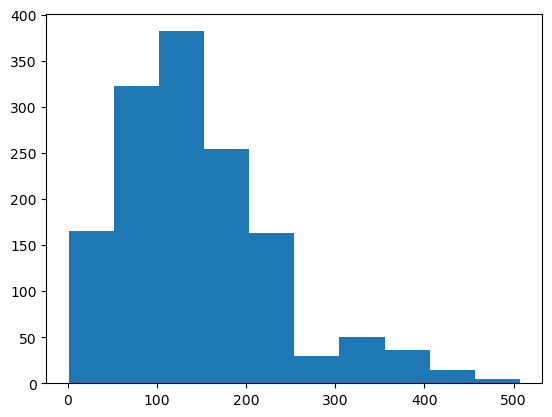

In [150]:
plt.hist(df_detections["detection_size"])

In [166]:
def add_snr(df, half_aperture, tracking, fpath):
    """
    returns the dataframe with a new column of stdv ratios
    see get_sobel_ratio(stamp) and get_stdv_ratio
    """
    ratios_center = []
    ratios_max = []
    ratios_min = []
    for index in df.index:
        # print(index)
        tot, maxcols = get_tot_npy(df, index, half_aperture, tracking, fpath)
        stdv = rff.get_stdvs(tot, do_all=False, df=df, index=index)
        avg = np.average(tot)
        row = int(df.loc[index]["row_from_nn"]) + 10
        max_val = np.max(tot[row - 10 : row + 10])
        min_val = np.min(tot[row - 10 : row + 10])
        signal_center = tot[row] - avg
        signal_max = max_val - avg
        signal_min = min_val - avg
        ratios_center.append(signal_center / stdv)
        ratios_max.append(signal_max / stdv)
        ratios_min.append(signal_min / stdv)
    df["snr_center"] = ratios_center
    df["snr_max"] = ratios_max
    df["snr_min"] = ratios_min
    return df

In [153]:
df_detections["quadrant"] = np.full(len(df_detections), 1)

In [156]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

In [168]:
def get_tot_npy(
    df,
    index,
    half_aperture=2,
    tracking=True,
    fpath="/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/",
):
    """
    returns tot, maxcols: an array that is the flux of the star streak
    given an aperture that is halfaperture*2+1
    and if tracking=true, tracks when the streak posittion fluctuates
    oif tracking==false, goes based on average center of streak
    note: uses loc instead of iloc
    """
    wideval = half_aperture
    wid = 10
    fname = df.loc[index]["filename"] + "_1_implanted.npy"
    row = (
        int(df.loc[index]["row_from_nn"]) + 10
    )  # we add 10 here bc that's the cnn offset of returned values
    col = int(df.loc[index]["col_from_nn"]) + 10
    quad = int(df.loc[index]["quadrant"])
    column = int(col)

    path = fpath + fname
    # print(path)
    file1_array = np.load(path)
    # norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    image = file1_array

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    if tracking == False:
        zeropoint = col - 7
        averages = np.average(
            imagenobackground[row - 10 : row + 10, zeropoint : zeropoint + 14], axis=0
        )
        maxind = np.argmax(averages)
        tot2 = np.zeros(imagenobackground.shape[0])
        for r in range(
            0, imagenobackground.shape[0]
        ):  # this should be each row, probably
            maxcol = zeropoint + maxind
            combined = imagenobackground[r, maxcol]
            for i in range(1, half_aperture + 1):
                combined += imagenobackground[r, maxcol - i]
                combined += imagenobackground[r, maxcol + i]
            tot2[r] = combined
        return tot2, np.full(len(tot2), maxcol)

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 10
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint : zeropoint + 20]) + zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1, half_aperture + 1):
            combined += imagenobackground[r, maxcol - i]
            combined += imagenobackground[r, maxcol + i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = combined

    return tot, maxcols

In [169]:
df_detections_snr = add_snr(
    df_detections,
    half_aperture=2,
    tracking=True,
    fpath="/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/",
)

In [170]:
df_detections_snr.to_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections_snr"
)

In [255]:
df_detections_snr

,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,snr_center,snr_max,snr_min
0,ztf_20220820237546_000798_zr_c14_x_0004.,436,both,1148.768349,418.321101,429.0,1157.0,10.0,6.0,1,22.828026,22.844572,5.855043
1,ztf_20220820237546_000798_zr_c14_x_0004.,49,pos,2469.489796,1962.428571,1972.0,2480.0,1.3,4.0,1,12.950728,12.950728,0.193874
2,ztf_20220820237546_000798_zr_c14_x_0004.,106,pos,2093.462264,2060.264151,2070.0,2104.0,1.5,5.0,1,15.720354,17.117032,1.347213
3,ztf_20220820237546_000798_zr_c14_x_0004.,46,pos,1921.500000,366.456522,376.0,1933.0,1.3,5.0,1,6.999463,10.246230,0.523708
4,ztf_20220820237546_000798_zr_c14_x_0004.,55,pos,1752.927273,343.436364,353.0,1763.0,2.0,3.0,1,25.211079,30.131837,-0.859047
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1417,ztf_20221020138241_000686_zi_c06_x_0009.,76,pos,2379.657895,1297.000000,1306.0,2393.0,1.5,8.0,1,6.563228,6.831086,1.527257
1418,ztf_20221020138241_000686_zi_c06_x_0009.,126,pos,1115.468254,1761.730159,1771.0,1126.0,3.0,4.0,1,51.108499,57.099026,1.706610
1419,ztf_20221020138241_000686_zi_c06_x_0009.,82,pos,917.890244,1739.707317,1749.0,928.0,2.0,3.0,1,38.933385,40.383366,-1.468475
1420,ztf_20221020138241_000686_zi_c06_x_0009.,75,pos,494.226667,1033.960000,1044.0,505.0,1.3,4.0,1,13.493697,14.718185,0.186240


In [172]:
df_detections_snr_sorted = df_detections_snr.sort_values("snr_max")

In [173]:
df_detections_snr_sorted

,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,snr_center,snr_max,snr_min
1168,ztf_20220820237546_000798_zr_c09_x_0003.,8,pos,1478.000000,1909.500000,1923.0,1489.0,1.1,5.0,1,-0.542833,-0.007743,-2.132971
753,ztf_20220820237546_000798_zr_c12_x_0000.,19,pos,2219.105263,1503.842105,1513.0,2230.0,1.5,7.0,1,0.245687,0.245687,0.048470
769,ztf_20221020138241_000686_zi_c02_x_0021.,88,pos,1636.204545,2258.556818,2269.0,1647.0,2.0,5.0,1,-2.405915,0.458776,-2.405915
1276,ztf_20221020138241_000686_zi_c01_x_0006.,18,pos,1662.500000,1315.111111,1326.0,1672.0,1.3,3.0,1,-0.372019,0.617657,-1.378644
1037,ztf_20221014162894_000802_zg_c01_x_0018.,85,pos,2529.823529,2797.576471,2806.0,2541.0,2.0,8.0,1,-0.114075,0.836022,-1.640750
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1227,ztf_20221014162894_000802_zg_c02_x_0017.,339,both,1393.887906,1547.061947,1558.0,1403.0,6.0,3.0,1,353.567312,353.567312,-0.312317
862,ztf_20221014162894_000802_zg_c02_x_0029.,108,pos,2786.574074,1907.944444,1918.0,2797.0,10.0,3.0,1,410.577511,433.912612,1.268614
860,ztf_20221014162894_000802_zg_c02_x_0029.,388,both,2788.662371,1908.884021,1918.0,2797.0,10.0,3.0,1,501.413318,505.669184,2.417829
1359,ztf_20221014162894_000802_zg_c02_x_0022.,105,pos,1148.561905,2307.495238,2319.0,1159.0,8.0,3.0,1,490.453856,511.880969,1.238987


In [176]:
df_detections_snr_cleaned = df_detections_snr_sorted.drop_duplicates(
    subset=["filename", "row_from_implant", "col_from_implant"], keep="last"
)

In [180]:
len(df_detections_snr_cleaned)

1252

In [184]:
df_detections_snr_cleaned[df_detections_snr_cleaned["A_from_implant"] < 1.3]

,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,snr_center,snr_max,snr_min
1168,ztf_20220820237546_000798_zr_c09_x_0003.,8,pos,1478.000000,1909.500000,1923.0,1489.0,1.10,5.0,1,-0.542833,-0.007743,-2.132971
205,ztf_20221020138241_000686_zi_c01_x_0019.,17,pos,1946.117647,1685.294118,1694.0,1956.0,1.10,4.0,1,1.461817,1.841378,-1.920931
1394,ztf_20221017148750_000831_zi_c03_x_0007.,3,pos,1678.000000,1925.000000,1936.0,1688.0,1.10,3.0,1,1.973146,2.370685,-2.316286
501,ztf_20221017148750_000831_zi_c03_x_0020.,21,pos,1059.190476,1393.952381,1404.0,1071.0,1.10,4.0,1,2.628650,2.881430,-0.435551
1195,ztf_20221014162894_000802_zg_c01_x_0011.,2,pos,488.500000,158.000000,171.0,498.0,1.05,4.0,1,2.533696,2.978286,-1.577449
1352,ztf_20221020138241_000686_zi_c01_x_0005.,1,pos,676.000000,1188.000000,1200.0,689.0,1.10,6.0,1,1.726310,3.068824,-2.724215
84,ztf_20221020138241_000686_zi_c06_x_0010.,7,pos,129.285714,1162.000000,1170.0,139.0,1.10,3.0,1,1.749447,3.140385,-1.871323
1146,ztf_20221014162894_000802_zg_c01_x_0013.,14,pos,975.285714,2788.357143,2800.0,986.0,1.10,3.0,1,3.276089,3.276089,-3.871198
222,ztf_20220820237546_000798_zr_c14_x_0003.,23,pos,2495.739130,2059.347826,2070.0,2505.0,1.10,3.0,1,1.350068,3.364378,-1.783820
111,ztf_20221020138241_000686_zi_c03_x_0018.,1,pos,775.000000,515.000000,527.0,785.0,1.05,4.0,1,3.390904,3.765153,-1.910845


(array([ 25.,   0., 125.,   0.,   0., 144.,   0.,   0.,   0.,   0., 157.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 166.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 154.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
        160.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
        163.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
        158.]),
 array([ 1.05  ,  1.1395,  1.229 ,  1.3185,  1.408 ,  1.4975,  1.587 ,
         1.6765,  1.766 ,  1.8555,  1.945 ,  2.0345,  2.124 ,  2.2135,
         2.303 ,  2.3925,  2.482 ,  2.5715,  2.661 ,  2.7505,  2.84  ,
         2.9295,  3.019 ,  3.1085,  3.198 ,  3.2875,  3.377 ,  3.4665,
         3.556 ,  3.6455,  3.735 ,

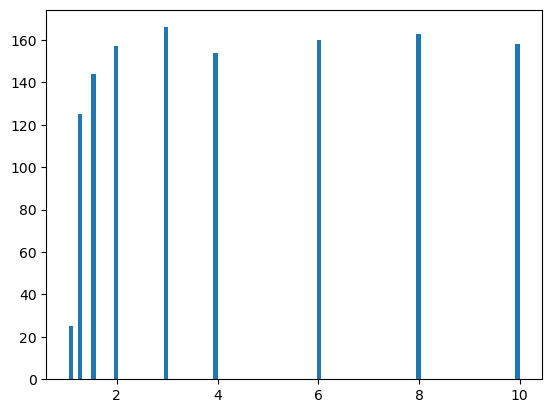

In [188]:
plt.hist(df_detections_snr_cleaned["A_from_implant"], bins=100)

In [190]:
df_detections_snr_cleaned

,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,snr_center,snr_max,snr_min
1168,ztf_20220820237546_000798_zr_c09_x_0003.,8,pos,1478.000000,1909.500000,1923.0,1489.0,1.1,5.0,1,-0.542833,-0.007743,-2.132971
753,ztf_20220820237546_000798_zr_c12_x_0000.,19,pos,2219.105263,1503.842105,1513.0,2230.0,1.5,7.0,1,0.245687,0.245687,0.048470
769,ztf_20221020138241_000686_zi_c02_x_0021.,88,pos,1636.204545,2258.556818,2269.0,1647.0,2.0,5.0,1,-2.405915,0.458776,-2.405915
1276,ztf_20221020138241_000686_zi_c01_x_0006.,18,pos,1662.500000,1315.111111,1326.0,1672.0,1.3,3.0,1,-0.372019,0.617657,-1.378644
1037,ztf_20221014162894_000802_zg_c01_x_0018.,85,pos,2529.823529,2797.576471,2806.0,2541.0,2.0,8.0,1,-0.114075,0.836022,-1.640750
...,...,...,...,...,...,...,...,...,...,...,...,...,...
876,ztf_20221014162894_000802_zg_c03_x_0018.,114,pos,513.605263,1364.614035,1375.0,524.0,10.0,3.0,1,320.797698,341.104578,-0.674265
417,ztf_20221017148750_000831_zi_c01_x_0024.,346,both,1454.303468,2867.537572,2877.0,1465.0,10.0,3.0,1,331.826746,347.296735,0.153457
1227,ztf_20221014162894_000802_zg_c02_x_0017.,339,both,1393.887906,1547.061947,1558.0,1403.0,6.0,3.0,1,353.567312,353.567312,-0.312317
860,ztf_20221014162894_000802_zg_c02_x_0029.,388,both,2788.662371,1908.884021,1918.0,2797.0,10.0,3.0,1,501.413318,505.669184,2.417829


In [193]:
df_detections_snr_cleaned.loc[1168]["detection_size"]

8

In [194]:
importlib.reload(fitting)

<module 'fitting' from '/home/3155/fitting.py'>

In [220]:
def fit_df(df):
    dumbcounter = 0
    optimized_M_arr = np.zeros(len(df))
    optimized_sig_arr = np.zeros(len(df))
    optimized_A_arr = np.zeros(len(df))
    optimized_streak_val_arr = np.zeros(len(df))
    min_val_arr = np.zeros(len(df))

    for i, index in enumerate(df.index):
        tot, maxcols = get_tot_npy(
            df,
            index,
            half_aperture=2,
            tracking=True,
            fpath="/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/",
        )
        sig_guess = np.sqrt(df.loc[index]["detection_size"])
        M_guess = int(df.loc[index]["row_from_nn"]) + 10

        if M_guess - 60 < 0 or M_guess + 61 > len(tot):
            df.drop(index, inplace=True)
            dumbcounter += 1
            continue

        streak_val_guess = np.mean(
            np.append(
                tot[M_guess - 60 : M_guess - 10], tot[M_guess + 10 : M_guess + 61]
            )
        )
        A_guess = tot[int(M_guess)] / streak_val_guess
        (
            optimized_M,
            optimized_sig,
            optimized_A,
            optimized_streak_val,
            min_val,
        ) = fitting.fit_params(M_guess, sig_guess, A_guess, streak_val_guess, tot)
        print(M_guess, sig_guess, A_guess, streak_val_guess)
        print(optimized_M, optimized_sig, optimized_A, optimized_streak_val, min_val)

        optimized_M_arr[i - dumbcounter] = optimized_M
        optimized_sig_arr[i - dumbcounter] = optimized_sig
        optimized_A_arr[i - dumbcounter] = optimized_A
        optimized_streak_val_arr[i - dumbcounter] = optimized_streak_val
        min_val_arr[i - dumbcounter] = min_val
    df["optimized_M"] = optimized_M_arr[: len(df)]
    df["optimized_sig"] = optimized_sig_arr[: len(df)]
    df["optimized_A"] = optimized_A_arr[: len(df)]
    df["optimized_streak_val"] = optimized_streak_val_arr[: len(df)]
    df["min_val"] = min_val_arr[: len(df)]

    return df

In [221]:
df_detections_fit = fit_df(df_detections_snr_cleaned)

1488 2.8284271247461903 1.0006755683765383 1.5975560575428576
1466.230833895666 41.725810981858245 0.8866881449375267 1.7249949971073746 4.029501006600237
2229 4.358898943540674 0.740877511155475 0.28245971196948894
2230.096938934284 6.559861742428758 1.3447867282019368 0.14525921482702844 14.524960441582568
1646 9.38083151964686 0.977306653273224 0.2786060884447381
1645.9905481996525 9.386185991746267 1.0115126627859161 0.2778050050440766 0.5172052884526771
1672 4.242640687119285 1.0190098752800574 0.2296796225675262
1672.0000692330068 4.242679185503529 1.0219770129696188 0.22901278571255626 0.6290482681796069
2539 9.219544457292887 1.0078738287340896 0.29522443289803985
2538.9998126965434 9.219166573467454 1.0012906117623057 0.2949699373785198 0.6345021197472658
735 7.745966692414834 1.5186120023987146 0.16558648601616963
735.9164405380252 3.8899795072936785 4.084849218358065 0.06535375138330507 10.309913661585167
1042 7.681145747868608 1.0274977013119106 0.437806637865482
1027.36620

/tmp/ipykernel_33470/4254651986.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(index, inplace=True)


250 13.92838827718412 4.954202662896866 0.4185034499900176
251.97190335720916 6.9213714560161455 5.888707613283697 0.3657433845818172 1.595673878883924
194 11.704699910719626 5.05515629123212 0.0549114778047741
195.8417368856722 6.944870972515827 5.929421209028937 0.04789233354309513 0.14894051836408065
1050 13.114877048604 2.8508706702220787 0.17041511022218384
1051.5753260518984 7.063258200015026 3.0201879619126633 0.16079997079382768 0.5797360749783131
1916 13.564659966250536 4.765682280621123 0.5008711850289072
1917.9485607493987 6.886841356976691 5.977995255334418 0.4359646643144907 1.5801111239303416
177 13.30413469565007 2.7018301211516453 0.4595666309394459
178.96078203369152 6.909124194690029 2.89786154734928 0.43631080763786234 0.8595389350889462
289 13.30413469565007 5.125113128248369 0.19483419987234737
290.96215982331654 7.032403974569 5.711137194027787 0.16920977430394785 0.7847222685200568
2075 12.806248474865697 2.863819447918357 0.2939792549846196
2076.971876475569 7.0

/tmp/ipykernel_33470/4254651986.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(index, inplace=True)


2828 7.211102550927978 1.2964553025805645 0.174160432254914
2828.4738502017026 3.036945377985551 1.2996005693259682 0.17412770528501348 0.39725434847561264
2404 8.366600265340756 4.5527306425560345 0.01690102272694654
2405.87897602939 6.704089318419918 5.738936790679454 0.015010019084459226 0.16422028122760954
2498 9.16515138991168 1.3016713760415413 0.512769470415493
2498.6010661919527 4.838115283619817 1.2920635817003758 0.5116187291441341 1.13017158431162
2943 12.922847983320086 4.524265926323901 0.08134273262602268
2945.9515058788174 6.033009878534722 5.876856974265483 0.07334011658445577 0.42649830524525967
2760 4.898979485566356 1.2770461286285673 0.07570477936527517
2761.8750357836934 5.054655471379074 1.287844817644383 0.07541528695631043 0.14031885803179311
1571 12.68857754044952 1.961278024281897 1.0739233198732432
1573.3607698970739 6.255702028624025 2.0533107474962686 1.0443038653691956 2.956092075077995
2120 13.228756555322953 2.6744274326364468 0.2438679502742125
2121.858

...

/tmp/ipykernel_33470/4254651986.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(index, inplace=True)


755 10.535653752852738 2.852559370592689 0.5758687635459522
756.01680496295 2.9592987108383126 3.006050850739137 0.5755667188946224 1.265110748215744
833 9.219544457292887 6.87010382495617 0.04360188259789259
833.9967193336618 3.8715199038303076 7.614836879309916 0.04320039971258516 0.2636098765672462
1544 9.273618495495704 3.7328949294557523 0.21868842781180203
1544.9912279733066 2.960485889915969 3.920162103763262 0.21775222151318976 0.7639550689847762
2858 11.61895003862225 6.9447800946991975 0.12473335869536542
2858.905156554538 4.045967039789559 7.256687586417012 0.12258676098622709 0.5118267403301445
1340 7.211102550927978 3.5513367943796053 0.02565157572084134
1340.9382981667086 2.8418487652906697 4.002471186969702 0.02560116995248494 0.1121981329736723
2314 19.209372712298546 2.958660611845162 0.6813016628274823
2314.1318144222737 3.9661582589594873 3.0140594298113808 0.6779377304223798 1.2923728515653266
1253 17.46424919657298 7.350600809867118 0.05216007111686291
1252.0762899

/tmp/ipykernel_33470/4254651986.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(index, inplace=True)


1479 17.349351572897472 5.533592407463488 0.22923963184994045
1478.0566432582352 2.9919958258330515 5.85262187159126 0.22873738641287092 0.6807478031420796
2503 10.246950765959598 5.477684437590562 0.30045461772692084
2504.011002941877 3.014205851391589 5.841011697354735 0.3006387759394066 0.8447873705696088
1490 17.72004514666935 7.592802658901604 0.2656540909025929
1481.852267731177 21.479479998284006 1.1140289242862729 0.2583992761554172 13.242512199677591
434 19.1049731745428 7.831563106146214 0.45635770423577565
432.2603686372387 31.4865251991315 1.062382380538678 0.4460729904338996 24.466015502232572
2138 10.535653752852738 5.488891284338578 0.2683745498704438
2139.0416318543853 2.9816704707166934 5.792330863845022 0.2674123346689343 0.7306876166395082
927 18.947295321496416 9.703451938709344 0.31083754767285715
925.1317163533133 33.32741649966042 1.1418684144556446 0.28875160017898527 21.024031668713747
2264 17.233687939614086 5.865282676733215 0.1064360113722263
2264.0273994098

/tmp/ipykernel_33470/4254651986.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["optimized_M"] = optimized_M_arr[:len(df)]
/tmp/ipykernel_33470/4254651986.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["optimized_sig"] = optimized_sig_arr[:len(df)]
/tmp/ipykernel_33470/4254651986.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydat

In [223]:
df_detections_fit.to_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections_fit"
)

In [43]:
df_detections_fit

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,snr_center,snr_max,snr_min,optimized_M,optimized_sig,optimized_A,optimized_streak_val,min_val
0,1168,ztf_20220820237546_000798_zr_c09_x_0003.,8,pos,1478.000000,1909.500000,1923.0,1489.0,1.1,5.0,1,-0.542833,-0.007743,-2.132971,1466.230834,41.725811,0.886688,1.724995,4.029501
1,753,ztf_20220820237546_000798_zr_c12_x_0000.,19,pos,2219.105263,1503.842105,1513.0,2230.0,1.5,7.0,1,0.245687,0.245687,0.048470,2230.096939,6.559862,1.344787,0.145259,14.524960
2,769,ztf_20221020138241_000686_zi_c02_x_0021.,88,pos,1636.204545,2258.556818,2269.0,1647.0,2.0,5.0,1,-2.405915,0.458776,-2.405915,1645.990548,9.386186,1.011513,0.277805,0.517205
3,1276,ztf_20221020138241_000686_zi_c01_x_0006.,18,pos,1662.500000,1315.111111,1326.0,1672.0,1.3,3.0,1,-0.372019,0.617657,-1.378644,1672.000069,4.242679,1.021977,0.229013,0.629048
4,1037,ztf_20221014162894_000802_zg_c01_x_0018.,85,pos,2529.823529,2797.576471,2806.0,2541.0,2.0,8.0,1,-0.114075,0.836022,-1.640750,2538.999813,9.219167,1.001291,0.294970,0.634502
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1237,876,ztf_20221014162894_000802_zg_c03_x_0018.,114,pos,513.605263,1364.614035,1375.0,524.0,10.0,3.0,1,320.797698,341.104578,-0.674265,523.965565,2.946802,10.461926,0.301314,1.085812
1238,417,ztf_20221017148750_000831_zi_c01_x_0024.,346,both,1454.303468,2867.537572,2877.0,1465.0,10.0,3.0,1,331.826746,347.296735,0.153457,1465.003885,2.977322,9.499952,0.172200,0.419062
1239,1227,ztf_20221014162894_000802_zg_c02_x_0017.,339,both,1393.887906,1547.061947,1558.0,1403.0,6.0,3.0,1,353.567312,353.567312,-0.312317,1403.221710,21.939477,1.003919,0.499101,19.230702
1240,860,ztf_20221014162894_000802_zg_c02_x_0029.,388,both,2788.662371,1908.884021,1918.0,2797.0,10.0,3.0,1,501.413318,505.669184,2.417829,2796.959895,41.712466,1.036557,0.152688,10.761468


In [225]:
np.unique(df_detections_fit["A_from_implant"])

array([ 1.05,  1.1 ,  1.3 ,  1.5 ,  2.  ,  3.  ,  4.  ,  6.  ,  8.  ,
       10.  ])

In [226]:
np.mean((df_detections_fit["A_from_implant"] - df_detections_fit["optimized_A"]) ** 2)

1.5687411365077104

In [234]:
# now getting mse for each
mses_A = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
mses_sig = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
mses_M = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
numbers = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
for i, A_val in enumerate(np.unique(df_detections_fit["A_from_implant"])):
    df = df_detections_fit[df_detections_fit["A_from_implant"] == A_val]
    if len(df) > 100:
        df = df[:100]
    mse_A = np.mean((df["A_from_implant"] - df["optimized_A"]) ** 2)
    mse_sig = np.mean((df["sig_from_implant"] - df["optimized_sig"]) ** 2)
    mse_M = np.mean((df["col_from_implant"] - df["optimized_M"]) ** 2)
    mses_A[i] = mse_A
    mses_sig[i] = mse_sig
    mses_M[i] = mse_M
    numbers[i] = len(df)

In [237]:
mses_sig

array([1.29043164e+00, 7.10761079e+01, 4.03101649e-01, 2.81433693e-01,
       1.96127417e+01, 5.14953437e-01, 1.25521438e+00, 1.32881321e-02,
       1.55705441e-01, 8.83797442e-03])

In [238]:
mses_M

array([1.34305588e+00, 2.91820945e+01, 5.47980624e-01, 2.06850573e-01,
       2.24915017e+00, 9.66149442e-02, 3.17393877e-01, 1.81857313e-02,
       2.74420084e-02, 1.34393762e-02])

In [239]:
mses_A

array([0.00151881, 0.00275124, 0.00312263, 0.00331636, 0.05315533,
       0.05956287, 0.38915872, 0.13173264, 0.66853153, 0.34088626])

In [240]:
numbers

array([  5.,  20., 100., 100., 100., 100., 100., 100., 100., 100.])

In [248]:
pd.DataFrame(
    [
        np.unique(df_detections_fit["A_from_implant"]).T,
        numbers.T,
        mses_sig.T,
        mses_M.T,
        mses_A.T,
    ]
)

,0,1,2,3,4,5,6,7,8,9
0,1.050000,1.100000,1.300000,1.500000,2.000000,3.000000,4.000000,6.000000,8.000000,10.000000
1,5.000000,20.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
2,1.290432,71.076108,0.403102,0.281434,19.612742,0.514953,1.255214,0.013288,0.155705,0.008838
3,1.343056,29.182094,0.547981,0.206851,2.249150,0.096615,0.317394,0.018186,0.027442,0.013439
4,0.001519,0.002751,0.003123,0.003316,0.053155,0.059563,0.389159,0.131733,0.668532,0.340886


In [253]:
# percents
percents_A = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
percents_sig = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
percents_M = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
numbers = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
for i, A_val in enumerate(np.unique(df_detections_fit["A_from_implant"])):
    df = df_detections_fit[df_detections_fit["A_from_implant"] == A_val]
    if len(df) > 100:
        df = df[:100]
    percent_A = np.sum(
        ((df["A_from_implant"] - df["optimized_A"]) ** 2) / (df["A_from_implant"]) ** 2
    )
    percent_sig = np.sum(
        ((df["sig_from_implant"] - df["optimized_sig"]) ** 2)
        / (df["A_from_implant"]) ** 2
    )
    percent_M = np.sum(
        ((df["col_from_implant"] - df["optimized_M"]) ** 2)
        / (df["A_from_implant"]) ** 2
    )
    percents_A[i] = percent_A / len(df)
    percents_sig[i] = percent_sig / len(df)
    percents_M[i] = percent_M / len(df)
    numbers[i] = len(df)

In [259]:
df_percents = pd.DataFrame(
    [
        np.unique(df_detections_fit["A_from_implant"]).T,
        numbers.T,
        percents_sig.T,
        percents_M.T,
        percents_A.T,
    ]
)

In [260]:
df_percents.to_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_percents_neg"
)

In [2]:
import pandas as pd

In [15]:
df_percents2

,Unnamed: 0,0,1,2,3,4,5
0,0,0.800000,0.850000,0.900000,0.950000,0.990000,0.995000
1,1,100.000000,100.000000,61.000000,18.000000,17.000000,20.000000
2,2,136.782073,95.683259,22.273086,21.675951,214.533082,18.588675
3,3,93.598828,51.594543,31.098305,91.095847,119.428912,61.945388
4,4,0.063232,0.667343,0.019406,0.003825,0.004319,1.823058


In [14]:
df_percents2 = pd.read_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_percents_neg2"
)

In [25]:
df_detections_fit = pd.read_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections_fit"
)

In [35]:
# percents
percents_A = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
percents_sig = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
numbers = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
diffs_M = np.zeros(len(np.unique(df_detections_fit["A_from_implant"])))
for i, A_val in enumerate(np.unique(df_detections_fit["A_from_implant"])):
    df = df_detections_fit[df_detections_fit["A_from_implant"] == A_val]
    if len(df) > 100:
        df = df[:100]
    percent_A = np.sum(
        ((df["A_from_implant"] - df["optimized_A"]) ** 2) / (df["A_from_implant"]) ** 2
    )
    percent_sig = np.sum(
        ((df["sig_from_implant"] - df["optimized_sig"]) ** 2)
        / (df["A_from_implant"]) ** 2
    )
    # percent_M = np.sum(((df['col_from_implant'] - df['optimized_M']) ** 2)/(df['A_from_implant'])**2) #WAS COLUMN
    diff_M = np.average(
        np.abs(df["col_from_implant"] - df["optimized_M"]) / df["row_from_implant"]
    )
    percents_A[i] = percent_A / len(df)
    percents_sig[i] = percent_sig / len(df)
    numbers[i] = len(df)
    diffs_M[i] = diff_M

df_percents = pd.DataFrame(
    [
        np.unique(df_detections_fit["A_from_implant"]).T,
        numbers.T,
        percents_sig.T,
        diffs_M.T,
        percents_A.T,
    ]
)

# df_percents.to_csv("/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_percents_neg2")

In [36]:
df_percents

,0,1,2,3,4,5,6,7,8,9
0,1.050000,1.100000,1.300000,1.500000,2.000000,3.000000,4.000000,6.000000,8.000000,10.000000
1,5.000000,20.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
2,1.170460,58.740585,0.238522,0.125082,4.903185,0.057217,0.078451,0.000369,0.002433,0.000088
3,0.002142,0.002828,0.000878,0.000599,0.000370,0.000308,0.000247,0.000178,0.000116,0.000088
4,0.001378,0.002274,0.001848,0.001474,0.013289,0.006618,0.024322,0.003659,0.010446,0.003409


In [28]:
df_fit_neg = pd.read_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections_fit_neg"
)

In [29]:
# percents
percents_A = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
percents_sig = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
numbers = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
diffs_M = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
for i, A_val in enumerate(np.unique(df_fit_neg["A_from_implant"])):
    df = df_fit_neg[df_fit_neg["A_from_implant"] == A_val]
    if len(df) > 100:
        df = df[:100]
    percent_A = np.sum(
        ((df["A_from_implant"] - df["optimized_A"]) ** 2) / (df["A_from_implant"]) ** 2
    )
    percent_sig = np.sum(
        ((df["sig_from_implant"] - df["optimized_sig"]) ** 2)
        / (df["A_from_implant"]) ** 2
    )
    # percent_M = np.sum(((df['col_from_implant'] - df['optimized_M']) ** 2)/(df['A_from_implant'])**2) #WAS COLUMN
    diff_M = np.average(
        np.abs(df["row_from_implant"] - df["optimized_M"]) / df["row_from_implant"]
    )
    percents_A[i] = percent_A / len(df)
    percents_sig[i] = percent_sig / len(df)
    numbers[i] = len(df)
    diffs_M[i] = diff_M

df_percents_neg = pd.DataFrame(
    [
        np.unique(df_fit_neg["A_from_implant"]).T,
        numbers.T,
        percents_sig.T,
        diffs_M.T,
        percents_A.T,
    ]
)

# df_percents.to_csv("/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_percents_neg2")

In [30]:
df_percents_neg

,0,1,2,3,4,5
0,0.800000,0.850000,0.900000,0.950000,0.990000,0.995000
1,100.000000,100.000000,61.000000,18.000000,17.000000,20.000000
2,136.782073,95.683259,22.273086,21.675951,214.533082,18.588675
3,2.736884,1.038439,5.894993,1.036513,1.748046,4.375276
4,0.063232,0.667343,0.019406,0.003825,0.004319,1.823058


In [78]:
# percents

df_fit_neg = pd.read_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections_fit_neg"
)

df_fit_neg = pd.concat([df_fit_neg, df_detections_fit], ignore_index=True)


percents_A = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
percents_sig = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
numbers = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
diffs_M = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
pixels_M = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
pixels_sig = np.zeros(len(np.unique(df_fit_neg["A_from_implant"])))
for i, A_val in enumerate(np.unique(df_fit_neg["A_from_implant"])):
    df = df_fit_neg[df_fit_neg["A_from_implant"] == A_val]
    if len(df) > 100:
        df = df[:100]
    percent_A = np.average(
        np.abs(((df["A_from_implant"] - df["optimized_A"])) / (df["A_from_implant"]))
    )
    percent_sig = np.average(
        np.abs(
            ((df["sig_from_implant"] - df["optimized_sig"])) / (df["A_from_implant"])
        )
    )
    # percent_M = np.sum(((df['col_from_implant'] - df['optimized_M']) ** 2)/(df['A_from_implant'])**2) #WAS COLUMN
    diff_M = np.average(
        np.abs(df["col_from_implant"] - df["optimized_M"]) / df["col_from_implant"]
    )
    pixel_M = np.average(np.abs(df["col_from_implant"] - df["optimized_M"]))
    pixel_sig = np.average(np.abs(((df["sig_from_implant"] - df["optimized_sig"]))))
    percents_A[i] = percent_A
    percents_sig[i] = percent_sig
    numbers[i] = len(df)
    diffs_M[i] = diff_M
    pixels_sig[i] = pixel_sig
    pixels_M[i] = pixel_M

df_percents_neg3 = pd.DataFrame(
    [
        np.unique(df_fit_neg["A_from_implant"]).T,
        numbers.T,
        percents_A.T,
        diffs_M.T,
        percents_sig.T,
        pixels_M.T,
        pixels_sig.T,
    ]
)

# df_pe

In [63]:
pd.set_option("display.float_format", "{:.2g}".format)
df_percents_neg3

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,0.8,0.85,0.9,0.95,0.99,0.99,1.1,1.1,1.3,1.5,2,3,4,6,8,10
1,1e+02,1e+02,66,28,26,29,5,20,1e+02,1e+02,1e+02,1e+02,1e+02,1e+02,1e+02,1e+02
2,0.24,0.24,0.11,0.15,0.31,0.56,0.029,0.026,0.024,0.025,0.05,0.037,0.061,0.035,0.036,0.034
3,0.0067,0.0065,0.0059,0.011,0.018,0.018,0.001,0.0022,0.00087,0.00039,0.00039,0.00019,0.0002,0.00015,0.00012,0.00014
4,6.5,5.7,5,8.3,12,12,0.92,2.4,0.49,0.36,0.37,0.19,0.2,0.098,0.11,0.084
5,5.3,4.9,3.7,5,5.6,4.2,0.89,2.8,0.35,0.25,0.41,0.069,0.076,0.013,0.014,0.0065
6,4.2,4.2,3.4,4.8,5.5,4.1,0.93,3,0.45,0.38,0.81,0.21,0.3,0.08,0.11,0.065


In [76]:
def format_value(value):
    """
    Format a value to three significant figures and use scientific notation if necessary.

    Parameters:
    value: The value to format.

    Returns:
    str: The formatted value as a string.
    """
    if isinstance(value, (int, float)):
        if isinstance(value, float) and abs(value) < 0.1:
            return f"{value:.2e}"
        return f"{value:.3g}"
    return str(value)


def dataframe_to_latex(df, caption=None, label=None, column_format=None):
    """
    Convert a Pandas DataFrame to a LaTeX tabular environment.

    Parameters:
    df (pd.DataFrame): The DataFrame to convert.
    caption (str, optional): Caption for the table.
    label (str, optional): Label for referencing the table in LaTeX.
    column_format (str, optional): Column formatting for LaTeX tabular (e.g., 'lcr' for left, center, right).

    Returns:
    str: A LaTeX-formatted table as a string.
    """
    # Transpose the DataFrame
    df = df.transpose()

    if column_format is None:
        column_format = "l" * len(df.columns)  # Default: left-align all columns

    latex_table = []

    # Begin tabular environment
    latex_table.append("\\begin{table}[ht]")
    latex_table.append("\\centering")

    # Add caption if provided
    if caption:
        latex_table.append(f"\\caption{{{caption}}}")

    # Add label if provided
    if label:
        latex_table.append(f"\\label{{{label}}}")

    # Begin tabular
    latex_table.append(f"\\begin{{tabular}}{{{column_format}}}")
    latex_table.append("\\hline")

    # # Add column headers
    # header = " & ".join(df.columns) + " \\\\"
    # latex_table.append(header)
    # latex_table.append("\\hline")

    # Add rows
    for _, row in df.iterrows():
        row_data = " & ".join(map(format_value, row)) + " \\\\"
        latex_table.append(row_data)
        latex_table.append("\\hline")

    latex_table.append("\\end{tabular}")
    latex_table.append("\\end{table}")

    # Join all lines into a single string
    return "\n".join(latex_table)

In [79]:
# data = {
#     "Column 1": [1, 2, 3],
#     "Column 2": ["A", "B", "C"],
#     "Column 3": [0.1, 0.00002, 12345.6789]
# }
# df = pd.DataFrame(data)

latex_code = dataframe_to_latex(
    df_percents_neg3, caption="Sample Table", label="tab:sample", column_format="lcr"
)
print(latex_code)

\begin{table}[ht]
\centering
\caption{Sample Table}
\label{tab:sample}
\begin{tabular}{lcr}
\hline
0.8 & 100 & 0.24 & 6.65e-03 & 5.25 & 6.48 & 4.2 \\
\hline
0.85 & 100 & 0.242 & 6.54e-03 & 4.94 & 5.67 & 4.2 \\
\hline
0.9 & 66 & 0.108 & 5.94e-03 & 3.73 & 4.96 & 3.36 \\
\hline
0.95 & 28 & 0.146 & 1.06e-02 & 5.04 & 8.29 & 4.79 \\
\hline
0.99 & 26 & 0.312 & 1.77e-02 & 5.6 & 12.5 & 5.55 \\
\hline
0.995 & 29 & 0.56 & 1.76e-02 & 4.16 & 11.8 & 4.14 \\
\hline
1.05 & 5 & 2.93e-02 & 1.00e-03 & 0.89 & 0.916 & 0.934 \\
\hline
1.1 & 20 & 2.59e-02 & 2.22e-03 & 2.76 & 2.44 & 3.04 \\
\hline
1.3 & 100 & 2.36e-02 & 8.74e-04 & 0.35 & 0.491 & 0.455 \\
\hline
1.5 & 100 & 2.49e-02 & 3.88e-04 & 0.251 & 0.359 & 0.377 \\
\hline
2 & 100 & 4.96e-02 & 3.94e-04 & 0.407 & 0.369 & 0.814 \\
\hline
3 & 100 & 3.70e-02 & 1.92e-04 & 6.90e-02 & 0.188 & 0.207 \\
\hline
4 & 100 & 6.12e-02 & 2.02e-04 & 7.57e-02 & 0.197 & 0.303 \\
\hline
6 & 100 & 3.53e-02 & 1.51e-04 & 1.33e-02 & 9.85e-02 & 7.97e-02 \\
\hline
8 & 100 & 3.63e-0

In [187]:
#let's see if we recreated these images faithfully
#we just have the negative ones right now
path1 = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/"
path2 = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/"

In [198]:
testname = "ztf_20220820237546_000798_zr_c02_x_0002._1_implanted_info_neg.npy"

In [189]:
f1 = np.load(path1+testname)
f2 = np.load(path2+testname)

In [192]:
f2_norm = (f2-np.min(f2))/(np.max(f2)-np.min(f2))

In [196]:
infopath1 = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/info/"
infopath2 = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/info/"

In [199]:
f1 = np.load(infopath1+testname)
f2 = np.load(infopath2+testname)

In [200]:
f1

array([[1.280e+02, 2.590e+03, 9.900e-01, 7.000e+00],
       [3.350e+02, 2.118e+03, 8.500e-01, 5.000e+00],
       [3.710e+02, 4.120e+02, 9.000e-01, 3.000e+00],
       [5.380e+02, 3.010e+02, 9.500e-01, 6.000e+00],
       [7.090e+02, 1.166e+03, 9.950e-01, 9.000e+00],
       [7.540e+02, 4.500e+02, 9.500e-01, 6.000e+00],
       [7.970e+02, 2.207e+03, 9.950e-01, 6.000e+00],
       [9.980e+02, 2.858e+03, 8.000e-01, 7.000e+00],
       [1.339e+03, 2.524e+03, 8.000e-01, 6.000e+00],
       [1.524e+03, 2.945e+03, 9.000e-01, 5.000e+00]])

In [201]:
f2

array([[1.280e+02, 2.590e+03, 9.900e-01, 7.000e+00],
       [3.350e+02, 2.118e+03, 9.500e-01, 5.000e+00],
       [3.710e+02, 4.120e+02, 9.950e-01, 3.000e+00],
       [5.380e+02, 3.010e+02, 9.500e-01, 6.000e+00],
       [7.090e+02, 1.166e+03, 9.950e-01, 9.000e+00],
       [7.540e+02, 4.500e+02, 9.500e-01, 6.000e+00],
       [7.970e+02, 2.207e+03, 9.950e-01, 6.000e+00],
       [9.980e+02, 2.858e+03, 9.500e-01, 7.000e+00],
       [1.339e+03, 2.524e+03, 9.900e-01, 6.000e+00],
       [1.524e+03, 2.945e+03, 8.000e-01, 5.000e+00]])

In [193]:
print(np.max(f1-f2_norm), np.min(f1-f2_norm))

0.058552146 -0.040315628


In [88]:
df_detections_neg = pd.read_csv("/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections_neg")

In [3]:
df_something

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,ztf_20221014162894_000802_zg_c01_x_0029.,11,neg,1787.363636,1807.727273,1819.0,1798.0,0.80,8.0
1,1,ztf_20221014162894_000802_zg_c01_x_0029.,31,neg,1602.838710,159.677419,170.0,1613.0,0.85,5.0
2,2,ztf_20221014162894_000802_zg_c01_x_0029.,41,neg,1198.000000,545.341463,556.0,1208.0,0.85,3.0
3,3,ztf_20221014162894_000802_zg_c01_x_0029.,37,neg,279.270270,2303.783784,2313.0,289.0,0.80,4.0
4,4,ztf_20221014162894_000802_zg_c01_x_0029.,7,pos,1801.285714,1807.571429,1819.0,1798.0,0.80,8.0
...,...,...,...,...,...,...,...,...,...,...
1479,1479,ztf_20221020138241_000686_zi_c05_x_0002.,14,neg,566.142857,1229.714286,1240.0,576.0,0.85,9.0
1480,1480,ztf_20221020138241_000686_zi_c05_x_0002.,1,neg,541.000000,586.000000,596.0,551.0,0.90,7.0
1481,1481,ztf_20221017148750_000831_zi_c03_x_0028.,22,neg,1727.090909,1487.954545,1498.0,1737.0,0.80,6.0
1482,1482,ztf_20221017148750_000831_zi_c03_x_0028.,42,neg,1087.142857,1393.071429,1405.0,1097.0,0.80,6.0


In [6]:
import os

In [27]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = (
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays"
)
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/"

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("alllist_neg")
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    filename_start = df["filename"][1]
    infopath = (
        path_to_save
        + "info/"
        + str(filename_start)
        + "_"
        + str(1)
        + "_implanted_info_neg.npy"
    )
    infos = np.load(infopath)
    # print(info)
    if counter == 0:
         df_implants["filename"] = np.full(len(infos),filename_start)

         df_implants["row_from_implant"] = infos[:,0]
         df_implants["col_from_implant"] = infos[:,1]
         df_implants["A_from_implant"] = infos[:,2]
         df_implants["sig_from_implant"] = infos[:,3]
         counter = 1
    else:
         print("adding")
         df_implants2 = pd.DataFrame([])

         df_implants2["filename"] = np.full(len(infos),filename_start)

         df_implants2["row_from_implant"] = infos[:,0]
         df_implants2["col_from_implant"] = infos[:,1]
         df_implants2["A_from_implant"] = infos[:,2]
         df_implants2["sig_from_implant"] = infos[:,3]

         df_implants = pd.concat(
            [df_implants2, df_implants], ignore_index=True
                    )
    

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding

In [43]:
!ls "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays/" | head -10 

ztf_20220820237546_000798_zr_c01_x_0003._1_implanted_neg.npy1alllist_neg
ztf_20220820237546_000798_zr_c01_x_0003._1_implanted.npy1alllist
ztf_20220820237546_000798_zr_c01_x_0003._1_implanted.npy1alllist_neg
ztf_20220820237546_000798_zr_c01_x_0003._1_implanted.npy2alllist
ztf_20220820237546_000798_zr_c01_x_0003._1_implanted.npy3alllist
ztf_20220820237546_000798_zr_c01_x_0003._1_implanted.npy4alllist
ztf_20220820237546_000798_zr_c01_x_0003._extraction_predsarray_neg_predsarray.npy
ztf_20220820237546_000798_zr_c01_x_0003._extraction_predsarray_predsarray.npy
ztf_20220820237546_000798_zr_c02_x_0000._1_implanted_neg.npy1alllist_neg
ztf_20220820237546_000798_zr_c02_x_0000._1_implanted.npy1alllist
ls: write error: Broken pipe


In [47]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = (
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays"
)
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/"

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("npy1alllist")
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    filename_start = df["filename"][1]
    infopath = (
        path_to_save
        + "info/"
        + str(filename_start)
        + "_"
        + str(1)
        + "_implanted_info.npy"
    )
    infos = np.load(infopath)
    # print(info)
    if counter == 0:
         df_implants["filename"] = np.full(len(infos),filename_start)

         df_implants["row_from_implant"] = infos[:,0]
         df_implants["col_from_implant"] = infos[:,1]
         df_implants["A_from_implant"] = infos[:,2]
         df_implants["sig_from_implant"] = infos[:,3]
         counter = 1
    else:
         print("adding")
         df_implants2 = pd.DataFrame([])

         df_implants2["filename"] = np.full(len(infos),filename_start)

         df_implants2["row_from_implant"] = infos[:,0]
         df_implants2["col_from_implant"] = infos[:,1]
         df_implants2["A_from_implant"] = infos[:,2]
         df_implants2["sig_from_implant"] = infos[:,3]

         df_implants = pd.concat(
            [df_implants2, df_implants], ignore_index=True
                    )
    

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding

In [49]:
df_implants_pos = df_implants

In [30]:
df_implants_neg = df_implants

In [51]:
len(np.unique(df_implants_neg["filename"]))

200

(array([488., 167., 167.,   0.,   0., 164.,   0.,   0.,   0.,   0.,   0.,
        166.,   0.,   0.,   0.,   0., 154.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0., 163.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0., 167.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0., 161.]),
 array([ 1.01  ,  1.1898,  1.3696,  1.5494,  1.7292,  1.909 ,  2.0888,
         2.2686,  2.4484,  2.6282,  2.808 ,  2.9878,  3.1676,  3.3474,
         3.5272,  3.707 ,  3.8868,  4.0666,  4.2464,  4.4262,  4.606 ,
         4.7858,  4.9656,  5.1454,  5.3252,  5.505 ,  5.6848,  5.8646,
         6.0444,  6.2242,  6.404 ,  6.5838,  6.7636,  6.9434,  7.1232,
         7.303 ,  7.4828,  7.6626,  7.8424,  8.0222,  8.202 ,  8.3818,
         8.5616,  8.7414,  8.9212,  9.101 ,  9.2808,  9.4606,  9.6404,
         9.8202, 10.    ]),
 <BarContainer object of 50 artists>)

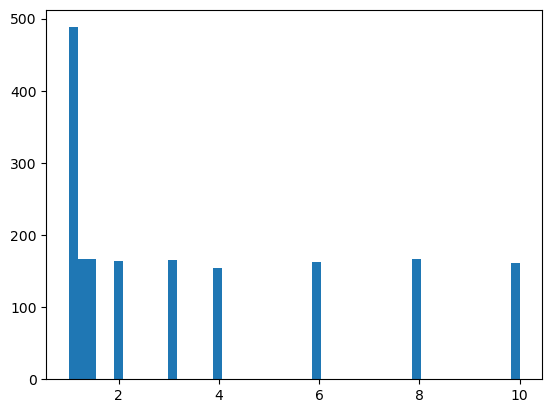

In [52]:
plt.hist(df_implants_pos["A_from_implant"], bins=50)

In [86]:
df_detections_pos = pd.read_csv("/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections")

(array([544.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0., 434.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0., 218.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,  88.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,  82., 118.]),
 array([0.8   , 0.8039, 0.8078, 0.8117, 0.8156, 0.8195, 0.8234, 0.8273,
        0.8312, 0.8351, 0.839 , 0.8429, 0.8468, 0.8507, 0.8546, 0.8585,
        0.8624, 0.8663, 0.8702, 0.8741, 0.878 , 0.8819, 0.8858, 0.8897,
        0.8936, 0.8975, 0.9014, 0.9053, 0.9092, 0.9131, 0.917 , 0.9209,
        0.9248, 0.9287, 0.9326, 0.9365, 0.9404, 0.9443, 0.9482, 0.9521,
        0.956 , 0.9599, 0.9638, 0.9677, 0.9716, 0.9755, 0.9794, 0.9833,
        0.9872, 0.9911, 0.995 ]),
 <BarContainer object of 50 artists>)

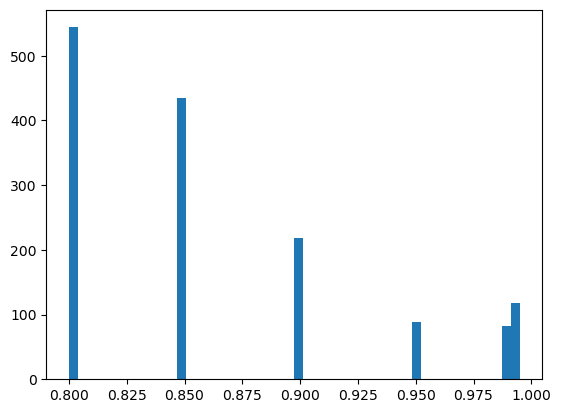

In [89]:
plt.hist(df_detections_neg["A_from_implant"], bins=50)

In [58]:
df_detections_neg

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,ztf_20221014162894_000802_zg_c01_x_0029.,11,neg,1787.363636,1807.727273,1819.0,1798.0,0.80,8.0
1,1,ztf_20221014162894_000802_zg_c01_x_0029.,31,neg,1602.838710,159.677419,170.0,1613.0,0.85,5.0
2,2,ztf_20221014162894_000802_zg_c01_x_0029.,41,neg,1198.000000,545.341463,556.0,1208.0,0.85,3.0
3,3,ztf_20221014162894_000802_zg_c01_x_0029.,37,neg,279.270270,2303.783784,2313.0,289.0,0.80,4.0
4,4,ztf_20221014162894_000802_zg_c01_x_0029.,7,pos,1801.285714,1807.571429,1819.0,1798.0,0.80,8.0
...,...,...,...,...,...,...,...,...,...,...
1479,1479,ztf_20221020138241_000686_zi_c05_x_0002.,14,neg,566.142857,1229.714286,1240.0,576.0,0.85,9.0
1480,1480,ztf_20221020138241_000686_zi_c05_x_0002.,1,neg,541.000000,586.000000,596.0,551.0,0.90,7.0
1481,1481,ztf_20221017148750_000831_zi_c03_x_0028.,22,neg,1727.090909,1487.954545,1498.0,1737.0,0.80,6.0
1482,1482,ztf_20221017148750_000831_zi_c03_x_0028.,42,neg,1087.142857,1393.071429,1405.0,1097.0,0.80,6.0


In [77]:
df_detections_pos = df_detections_pos.drop_duplicates(subset=["filename", "row_from_implant", "col_from_implant"])

In [79]:
df_detections_neg = df_detections_neg.drop_duplicates(subset=["filename", "row_from_implant", "col_from_implant"])

In [78]:
df_detections_pos

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,ztf_20220820237546_000798_zr_c14_x_0004.,436,both,1148.768349,418.321101,429.0,1157.0,10.0,6.0
1,1,ztf_20220820237546_000798_zr_c14_x_0004.,49,pos,2469.489796,1962.428571,1972.0,2480.0,1.3,4.0
2,2,ztf_20220820237546_000798_zr_c14_x_0004.,106,pos,2093.462264,2060.264151,2070.0,2104.0,1.5,5.0
3,3,ztf_20220820237546_000798_zr_c14_x_0004.,46,pos,1921.500000,366.456522,376.0,1933.0,1.3,5.0
4,4,ztf_20220820237546_000798_zr_c14_x_0004.,55,pos,1752.927273,343.436364,353.0,1763.0,2.0,3.0
...,...,...,...,...,...,...,...,...,...,...
1416,1416,ztf_20221020138241_000686_zi_c06_x_0009.,112,pos,2805.803571,1325.696429,1335.0,2817.0,8.0,4.0
1417,1417,ztf_20221020138241_000686_zi_c06_x_0009.,76,pos,2379.657895,1297.000000,1306.0,2393.0,1.5,8.0
1419,1419,ztf_20221020138241_000686_zi_c06_x_0009.,82,pos,917.890244,1739.707317,1749.0,928.0,2.0,3.0
1420,1420,ztf_20221020138241_000686_zi_c06_x_0009.,75,pos,494.226667,1033.960000,1044.0,505.0,1.3,4.0


In [91]:
#let's calculate efficiency at this step
df_implants_neg_big = df_implants_neg[df_implants_neg["A_from_implant"]<.9]

In [92]:
df_implants_pos_big = df_implants_pos[df_implants_pos["A_from_implant"]>1.1]

In [93]:
print(len(df_implants_pos_big), len(df_implants_neg_big))

1309 1218


In [94]:
df_detections_pos_big = df_detections_pos[df_detections_pos["A_from_implant"]>1.1]
df_detections_neg_big = df_detections_neg[df_detections_neg["A_from_implant"]<.9]

In [95]:
print(len(df_detections_pos_big), len(df_detections_neg_big))

1394 978


In [85]:
print("efficiency before doing postprocessing cuts:")
print(len(df_detections_pos_big)/len(df_implants_pos_big), len(df_detections_neg_big)/len(df_implants_neg_big))

efficiency before doing postprocessing cuts:
0.9373567608861727 0.2044334975369458


In [ ]:
#this is after dropping duplicates but we may not have dropped
#the best duplicate in the pair so let's go back and not do that

In [96]:
#i will combine them NO I CANT CAUSE THE IMAGES ARE SEPARATE
df_detections_big = pd.concat(
            [df_detections_pos_big, df_detections_neg_big], ignore_index=True
                    )
df_implants_big = pd.concat(
            [df_implants_pos_big, df_implants_neg_big], ignore_index=True
                    )

(array([1218.,    0.,    0.,    0.,    0.,  167.,    0.,  167.,    0.,
           0.,    0.,    0.,    0.,  164.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,  166.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,  154.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,  163.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,  167.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
         161.]),
 array([ 0.8  ,  0.892,  0.984,  1.076,  1.168,  1.26 ,  1.352,  1.444,
         1.536,  1.628,  1.72 ,  1.812,  1.904,  1.996,  2.088,  2.18 ,
         2.272,  2.364,  2.456,  2.548,  2.64 ,  2.732,  2

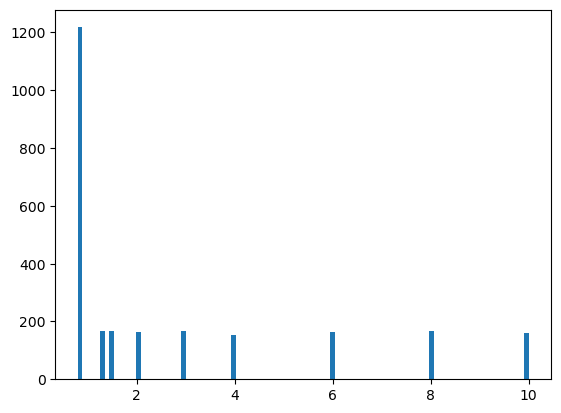

In [102]:
plt.hist(df_implants_big["A_from_implant"], bins=100)

In [116]:
#pos
df_nocr_pos = df_detections_pos_big[df_detections_pos_big["type"] != "cr"]
df_reduced_edges_pos= rff.reduce_edges(df_nocr_pos, 15)
df_reduced_edges_size4_pos = rff.reduce_size(df_reduced_edges_pos, 4)

Number of transient candidates reduced from 1393 to 1390.
Number of transient candidates reduced from 1390 to 1377.


In [106]:
import review_findings_functions as rff

In [ ]:
df_second = rff.reduce_max_3(df_reduced_edges_size4

In [ ]:
norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))

     Unnamed: 0                                  filename  detection_size  \
287         287  ztf_20220820237546_000798_zr_c01_x_0003.             248   
288         288  ztf_20220820237546_000798_zr_c01_x_0003.             196   
289         289  ztf_20220820237546_000798_zr_c01_x_0003.              77   
290         290  ztf_20220820237546_000798_zr_c01_x_0003.             161   
291         291  ztf_20220820237546_000798_zr_c01_x_0003.             130   
292         292  ztf_20220820237546_000798_zr_c01_x_0003.             270   
293         293  ztf_20220820237546_000798_zr_c01_x_0003.              54   
294         294  ztf_20220820237546_000798_zr_c01_x_0003.             134   

    type  row_from_nn  col_from_nn  row_from_implant  col_from_implant  \
287  pos  2818.024194  2794.681452            2803.0            2832.0   
288  pos  2575.357143   143.117347             151.0            2588.0   
289  pos  2555.558442  1372.623377            1383.0            2566.0   
290  pos  

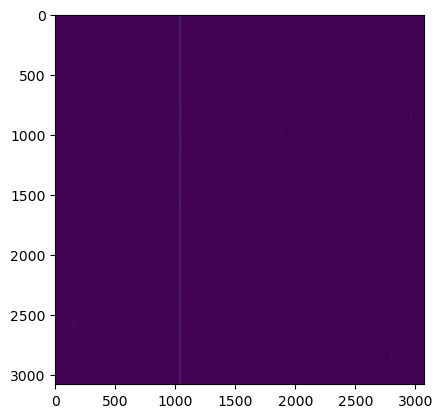

In [122]:
count=0
for filename in np.unique(df_reduced_edges_size4_pos["filename"]):
    df_for_file = df_reduced_edges_size4_pos[df_reduced_edges_size4_pos["filename"]==filename]
    print(df_for_file)
    fname = filename+"_1_implanted.npy"
    fpath = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/"
    path = fpath+fname
    # hdul=fits.open(path)
    # image = hdul[1].data
    image = np.load(path)
    #now have to scale it up...
    plt.imshow(image)
    background = rff.get_image_background(image)
#         #subtracting background
    imagenobackground = image - np.full(np.shape(image),background)
    reduced_df = rff.reduce_max_3(df_for_file, imagenobackground)
    if count==0:
        reduced_df2 = reduced_df
        count=1
    else:
        reduced_df2 = pd.concat(
            [reduced_df2, reduced_df], ignore_index=True
                    )
    break

In [125]:
background

0.0045558736

In [141]:
!ls "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images*_2_" | head -10

ls: cannot access /lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images*_2_: No such file or directory


In [ ]:
#now let's figure out the rest of the pipeline
'''
#     # Reduce based on type != 'cr'
    df_nocr = transients_df[transients_df["type"] != "cr"]
    for i, row in df_nocr.iterrows():
        # print(i)
        row_num = (int(row['row_from_nn'])+10)
        if i==df_nocr.index[0]:
            plt.axvline(x=row_num,c='thistle', label = "eliminated: too close to edges")
        else:
            plt.axvline(x=row_num,c='thistle')
    df_reduced_edges= reduce_edges(df_nocr, 15)
    for i, row in df_reduced_edges.iterrows():
        # print(i)
        row_num = (int(row['row_from_nn'])+10)
        if i==df_reduced_edges.index[0]:
            plt.axvline(x=row_num,c='paleturquoise', label = "eliminated: total size < 4 pixels")
        else:
            plt.axvline(x=row_num,c='paleturquoise')
    df_reduced_edges_size4 = reduce_size(df_reduced_edges, 4)
    for i, row in df_reduced_edges_size4.iterrows():
    # print(i)
        row_num = (int(row['row_from_nn'])+10)
        if i==df_reduced_edges_size4.index[0]:
            plt.axvline(x=row_num,c='lemonchiffon', label = "eliminated: not sufficiently bright")
        else:
            plt.axvline(x=row_num,c='lemonchiffon')
#     #reduce_max_3 got saved as a new df
    
    df_second = get_second_df_for_lc(lc_filename, tolerance=10)
    for i, row2 in df_second.iterrows():
        # print(i)
        row_num = (int(row2['row_from_nn'])+10)
        if i==df_second.index[0]:
            plt.axvline(x=row_num,c='lightsteelblue', label = "eliminated: sobel ratio < 5 (cosmic ray)")
        else:
            plt.axvline(x=row_num,c='lightsteelblue')  
    df_third = get_third_df_for_lc(lc_filename, tolerance=10)
    for i, row in df_third.iterrows():
    # print(i)
        row_num = (int(row['row_from_nn'])+10)
        if i==df_third.index[0]:
            plt.axvline(x=row_num,c='pink', label = "eliminated: local snr<1")
        else:
            plt.axvline(x=row_num,c='pink')
        if np.abs(row['snr_center'])>25:
            plt.axvline(x=row_num,c='orange', label = "eliminated: moving object (snr>25)")
            
    #i definitely did not include anything with SNR>25 at this point but i dont think i saved that
    #the only other strict cut was local snr>1
    #if i add the simultaneity criterion then i suppose i should put that here as well
    
    df_last = get_last_df_for_lc(lc_filename)
    '''

In [178]:
def add_snr(df, half_aperture, tracking, fpath, extension):
    """
    returns the dataframe with a new column of stdv ratios
    see get_sobel_ratio(stamp) and get_stdv_ratio
    """
    ratios_center = np.zeros(len(df))
    ratios_max = np.zeros(len(df))
    ratios_min = np.zeros(len(df))
    for i, index in enumerate(df.index):
        # print(index)
        tot, maxcols = get_tot_npy(df, index, extension, half_aperture, tracking, fpath)
        stdv = rff.get_stdvs(tot, do_all=False, df=df, index=index)
        avg = np.average(tot)
        row = int(df.loc[index]["row_from_nn"]) + 10
        max_val = np.max(tot[row - 10 : row + 10])
        min_val = np.min(tot[row - 10 : row + 10])
        signal_center = tot[row] - avg
        signal_max = max_val - avg
        signal_min = min_val - avg
        ratios_center[i] = signal_center / stdv
        ratios_max[i] = signal_max / stdv
        ratios_min[i] = signal_min / stdv
    df["snr_center"] = ratios_center
    df["snr_max"] = ratios_max
    df["snr_min"] = ratios_min
    return df




def get_tot_npy(
    df,
    index, extension,
    half_aperture=2,
    tracking=True,
    fpath="/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/",
):
    """
    returns tot, maxcols: an array that is the flux of the star streak
    given an aperture that is halfaperture*2+1
    and if tracking=true, tracks when the streak posittion fluctuates
    oif tracking==false, goes based on average center of streak
    note: uses loc instead of iloc
    """
    wideval = half_aperture
    wid = 10
    fname = df.loc[index]["filename"] + extension
    row = (
        int(df.loc[index]["row_from_nn"]) + 10
    )  # we add 10 here bc that's the cnn offset of returned values
    col = int(df.loc[index]["col_from_nn"]) + 10
    quad = int(df.loc[index]["quadrant"])
    column = int(col)

    path = fpath + fname
    # print(path)
    file1_array = np.load(path)
    # norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    image = file1_array

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    if tracking == False:
        zeropoint = col - 7
        averages = np.average(
            imagenobackground[row - 10 : row + 10, zeropoint : zeropoint + 14], axis=0
        )
        maxind = np.argmax(averages)
        tot2 = np.zeros(imagenobackground.shape[0])
        for r in range(
            0, imagenobackground.shape[0]
        ):  # this should be each row, probably
            maxcol = zeropoint + maxind
            combined = imagenobackground[r, maxcol]
            for i in range(1, half_aperture + 1):
                combined += imagenobackground[r, maxcol - i]
                combined += imagenobackground[r, maxcol + i]
            tot2[r] = combined
        return tot2, np.full(len(tot2), maxcol)

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 10
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint : zeropoint + 20]) + zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1, half_aperture + 1):
            combined += imagenobackground[r, maxcol - i]
            combined += imagenobackground[r, maxcol + i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = combined

    return tot, maxcols


def get_sobel_ratio(stamp):
    """
    input: stamp: 2d brightnesses array with candidate transient
    larger = less likely to be a cosmic ray
    returns sobel_ratio = np.max(Lx)/np.max(Ly) where x is columns axis and y is rows axis
    """
    
    Lx = sobel(stamp, axis=1)  # column axis
    Ly = sobel(stamp, axis=0)  # rows axis
    sobel_ratio = np.max(Lx) / np.max(Ly)  # we want this to be as large as possible
    return sobel_ratio


def get_stamp_from_df(index, fpath, df, extension, norm, quad=None):
    """
    returns a 20x20 numpy array of brightnesses centered around the detection
    located at index of dataframe df
    note that the filepath to the science images is hardcoded currently
    norm=True has the image normalized (not the stamp, the entire image)
    norm=False has it in terms of counts
    """
    fname = df.loc[index]["filename"] + extension
    row = int(df.loc[index]["row_from_nn"]) + 10
    col = int(df.loc[index]["col_from_nn"]) + 10
    if quad==None:
        quad = int(df.loc[index]["quadrant"])
    # if direcname == "0820":
    # fpath = (
    #     "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    #     + direcname
    #     + "_minus_extras/"
    # )
    # else:
    # fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"/"
    path = fpath + fname
    # hdul = fits.open(path)
    file1_array = np.load(path)
    if norm:
        normalized = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )  # norm
        stamp = normalized[row - 10 : row + 10, col - 10 : col + 10]
        # plt.imshow(stamp)
        # plt.colorbar()
        return stamp
        background = rff.get_image_background(normalized)
    stamp = file1_array[row - 10 : row + 10, col - 10 : col + 10]
    # plt.imshow(stamp)
    # plt.colorbar()
    background = rff.get_image_background(file1_array)
    plt.imshow(stamp)
    return stamp, background


def add_sobel_ratio(fpath, df, extension):
    """
    returns the dataframe with a new column of sobel ratios
    see get_sobel_ratio(stamp)
    """
    sobels = []
    for index in df_detections.index:
        stamp, bg = get_stamp_from_df(index, fpath, df, extension, norm=False)
        sobelr = get_sobel_ratio(stamp)
        sobels.append(sobelr)
    df["sobel_ratio"] = sobels
    return df

In [126]:
df_detections = df_reduced_edges_size4

In [127]:
df_detections["quadrant"] = np.full(len(df_detections), 1)

/tmp/ipykernel_44260/3934150145.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_detections["quadrant"] = np.full(len(df_detections), 1)


In [153]:
from scipy.ndimage import sobel

Int64Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
            ...
            2359, 2361, 2363, 2364, 2365, 2367, 2368, 2369, 2370, 2371],
           dtype='int64', length=2117)

/tmp/ipykernel_44260/493636520.py:166: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sobel_ratio"] = sobels


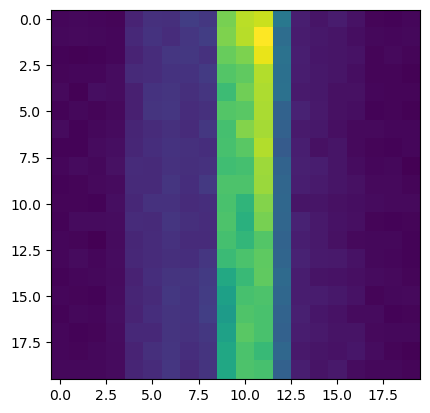

In [164]:
df_sobel_pos = add_sobel_ratio(fpath, df_detections, extension="_1_implanted.npy")

In [165]:
df_sobel = df_sobel_pos #note that this is currently
#incorrect cause all were calculated from pos images

In [169]:
np.sum(df_sobel["sobel_ratio"]<5)

413

In [179]:
df_sobel_snr = add_snr(df_sobel, half_aperture=2, tracking=True, fpath=fpath, extension="_1_implanted.npy")

/tmp/ipykernel_44260/3161920680.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["snr_center"] = ratios_center
/tmp/ipykernel_44260/3161920680.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["snr_max"] = ratios_max
/tmp/ipykernel_44260/3161920680.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/

(array([303., 446., 444., 245., 141.,  85.,  73.,  24.,  20.,  13.,  19.,
         14.,  12.,  13.,  11.,  19.,   8.,  13.,  19.,   9.,  12.,  12.,
          6.,   4.,   5.,   2.,   7.,   6.,   6.,  11.,   7.,   5.,   5.,
          3.,   8.,   4.,   7.,   3.,   9.,   2.,   6.,   7.,   2.,   1.,
          7.,   1.,   1.,   2.,   2.,   2.,   4.,   1.,   3.,   0.,   2.,
          1.,   0.,   1.,   1.,   1.,   1.,   2.,   3.,   1.,   1.,   2.,
          2.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,
          2.]),
 array([ -5.7665494 ,  -0.69475073,   4.37704794,   9.44884661,
         14.52064528,  19.59244395,  24.66424262,  29.73604129,
         34.80783996,  39.87963863,  44.9514373 ,  50.02323597,
         55.09503464,  60.16683331,  65.23863198,  70.31043065,
         75.38222932,  80.45402799,  85.52582666,  90.59762533

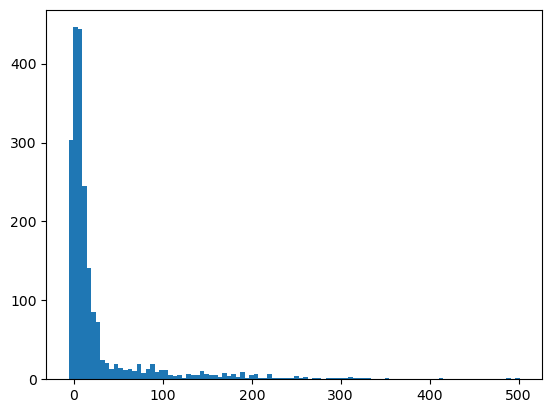

In [183]:
plt.hist(df_sobel_snr["snr_center"], bins=100)

In [202]:
big = df_sobel_snr[df_sobel_snr["snr_center"]>25]

In [216]:
np.sum([df_sobel_snr["A_from_implant"]>3])

766

In [214]:
np.sum([df_sobel_snr["snr_center"]>25])

443

(array([12., 42., 64., 68.,  0., 76.,  0., 87.,  0., 94.]),
 array([ 0.8 ,  1.72,  2.64,  3.56,  4.48,  5.4 ,  6.32,  7.24,  8.16,
         9.08, 10.  ]),
 <BarContainer object of 10 artists>)

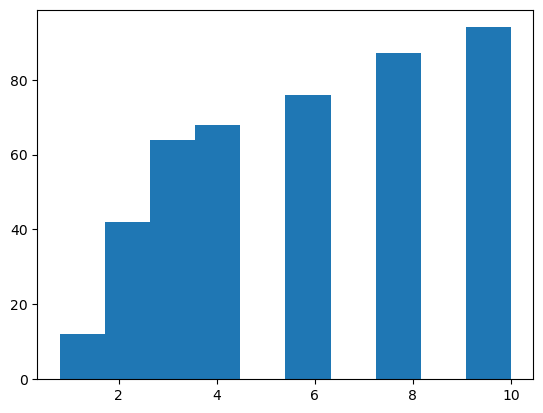

In [206]:
plt.hist(big["A_from_implant"])

In [ ]:
#todo: reducemax3, sobel

In [ ]:
#center snr<25, local snr cutoff, double streak
fpath